#PCD ASSIGNMENT 03

##MUSVI AULIA RAHARJO (25/559633/PA/23546)


In [51]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

Saving WhatsApp Image 2026-11-01 at 20.13.09.jpeg to WhatsApp Image 2026-11-01 at 20.13.09 (1).jpeg
Ukuran gambar: (640, 640, 3)
Tipe data awal: uint8


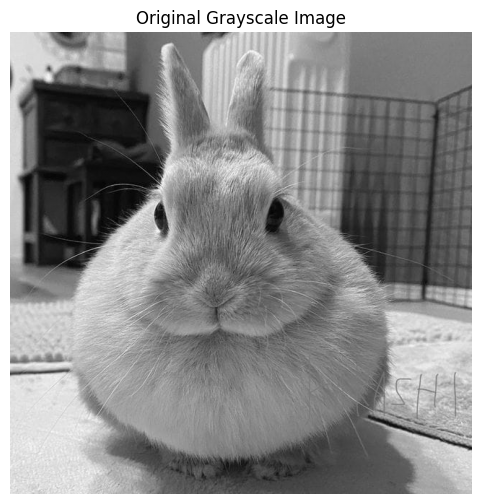

In [52]:
from google.colab import files

# Upload gambar dari komputer
uploaded = files.upload()

# Mengambil nama file yang di-upload
filename = list(uploaded.keys())[0]

# Membaca gambar
image = plt.imread(filename)

# Menampilkan ukuran dan tipe data gambar
print("Ukuran gambar:", image.shape)
print("Tipe data awal:", image.dtype)

# Mengubah gambar RGB menjadi grayscale jika diperlukan
if image.ndim == 3:
    image = image[:, :, :3]
    image = (
        0.299 * image[:, :, 0] +
        0.587 * image[:, :, 1] +
        0.114 * image[:, :, 2]
    )

# Mengubah nilai piksel ke rentang 0-255
if image.dtype != np.uint8:
    if image.max() <= 1:
        image = image * 255

    image = np.clip(image, 0, 255).round().astype(np.uint8)

# Menampilkan gambar grayscale
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()


In [53]:
def otsu_threshold(image):
    histogram = np.bincount(image.ravel(), minlength=256)

    total_pixels = image.size
    total_intensity = np.sum(
        np.arange(256) * histogram
    )

    sum_background = 0
    weight_background = 0
    max_variance = 0
    threshold = 0

    for t in range(256):
        weight_background += histogram[t]

        if weight_background == 0:
            continue

        weight_foreground = total_pixels - weight_background

        if weight_foreground == 0:
            break

        sum_background += t * histogram[t]

        mean_background = sum_background / weight_background
        mean_foreground = (
            total_intensity - sum_background
        ) / weight_foreground

        variance = (
            weight_background *
            weight_foreground *
            (mean_background - mean_foreground) ** 2
        )

        if variance > max_variance:
            max_variance = variance
            threshold = t

    return threshold


T = otsu_threshold(image)

print("Nilai threshold Otsu:", T)

Nilai threshold Otsu: 131


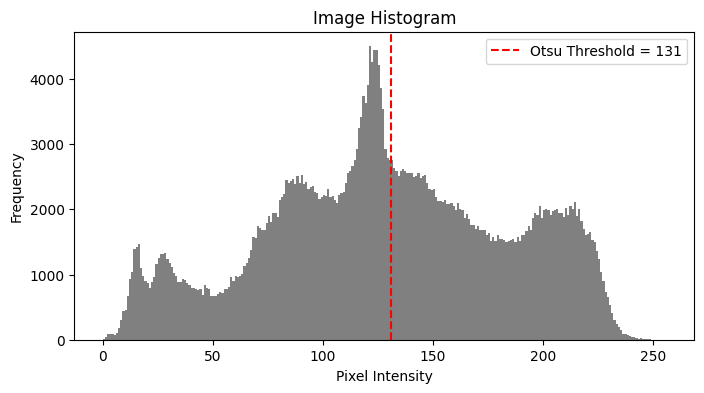

In [54]:
plt.figure(figsize=(8, 4))

plt.hist(image.ravel(), bins=256, range=(0, 256), color="gray")
plt.axvline(T, color="red", linestyle="--", label=f"Otsu Threshold = {T}")

plt.title("Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()

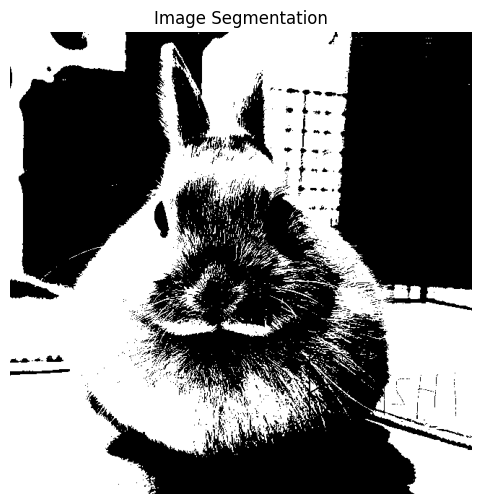

In [55]:
# Melakukan thresholding
segmented = image > T

# Mengubah hasil segmentasi menjadi citra biner
segmented = segmented.astype(np.uint8) * 255

# Menampilkan hasil segmentasi
plt.figure(figsize=(6, 6))
plt.imshow(segmented, cmap="gray")
plt.title("Image Segmentation")
plt.axis("off")
plt.show()

In [56]:
# Structuring element berukuran 3x3, 5x5, dan 7x7
SE_3 = np.ones((3, 3), dtype=np.uint8)
SE_5 = np.ones((5, 5), dtype=np.uint8)
SE_7 = np.ones((7, 7), dtype=np.uint8)

print("Structuring Element 3x3:")
print(SE_3)

print("\nStructuring Element 5x5:")
print(SE_5)

print("\nStructuring Element 7x7:")
print(SE_7)

Structuring Element 3x3:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

Structuring Element 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Structuring Element 7x7:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]


In [57]:
def erosion(image, se):
    image = image > 0

    se_height, se_width = se.shape
    pad_y = se_height // 2
    pad_x = se_width // 2

    # Padding putih sebagai nilai netral untuk erosion
    padded = np.pad(
        image,
        ((pad_y, pad_y), (pad_x, pad_x)),
        mode="constant",
        constant_values=True
    )

    result = np.ones(image.shape, dtype=bool)

    for y in range(se_height):
        for x in range(se_width):
            if se[y, x] == 1:
                region = padded[
                    y:y + image.shape[0],
                    x:x + image.shape[1]
                ]

                result = result & region

    return result.astype(np.uint8) * 255

In [58]:
def dilation(image, se):
    image = image > 0

    se_height, se_width = se.shape
    pad_y = se_height // 2
    pad_x = se_width // 2

    # Padding hitam sebagai nilai netral untuk dilation
    padded = np.pad(
        image,
        ((pad_y, pad_y), (pad_x, pad_x)),
        mode="constant",
        constant_values=False
    )

    result = np.zeros(image.shape, dtype=bool)

    for y in range(se_height):
        for x in range(se_width):
            if se[y, x] == 1:
                region = padded[
                    y:y + image.shape[0],
                    x:x + image.shape[1]
                ]

                result = result | region

    return result.astype(np.uint8) * 255

In [59]:
def opening(image, se):
    # Opening = Erosion dilanjutkan Dilation
    eroded = erosion(image, se)
    result = dilation(eroded, se)

    return result


def closing(image, se):
    # Closing = Dilation dilanjutkan Erosion
    dilated = dilation(image, se)
    result = erosion(dilated, se)

    return result

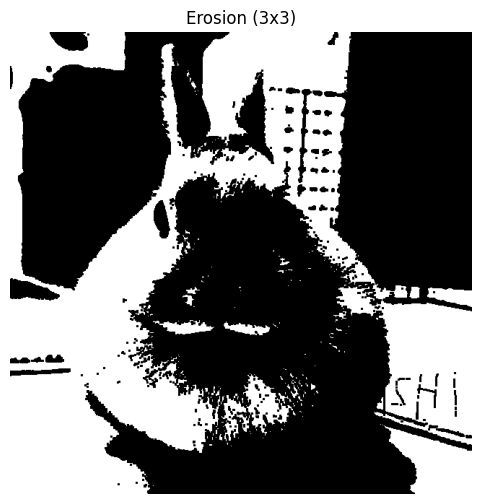

In [60]:
eroded_only = erosion(segmented, SE_3)

plt.figure(figsize=(6, 6))
plt.imshow(eroded_only, cmap="gray")
plt.title("Erosion (3x3)")
plt.axis("off")
plt.show()

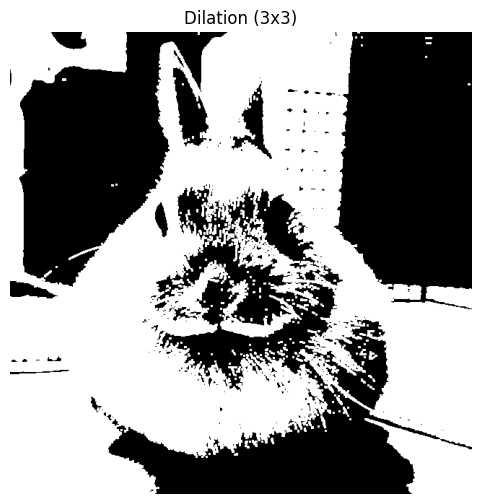

In [61]:
dilated_only = dilation(segmented, SE_3)

plt.figure(figsize=(6, 6))
plt.imshow(dilated_only, cmap="gray")
plt.title("Dilation (3x3)")
plt.axis("off")
plt.show()

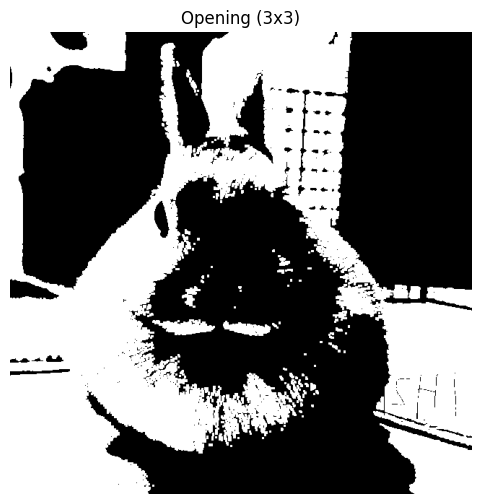

In [62]:
opened_only = opening(segmented, SE_3)

plt.figure(figsize=(6, 6))
plt.imshow(opened_only, cmap="gray")
plt.title("Opening (3x3)")
plt.axis("off")
plt.show()

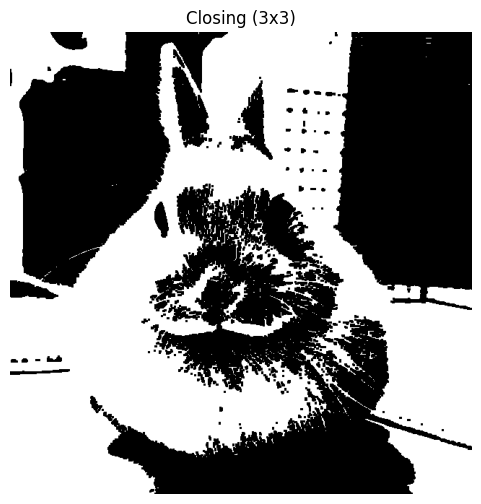

In [63]:
closed_only = closing(segmented, SE_3)

plt.figure(figsize=(6, 6))
plt.imshow(closed_only, cmap="gray")
plt.title("Closing (3x3)")
plt.axis("off")
plt.show()

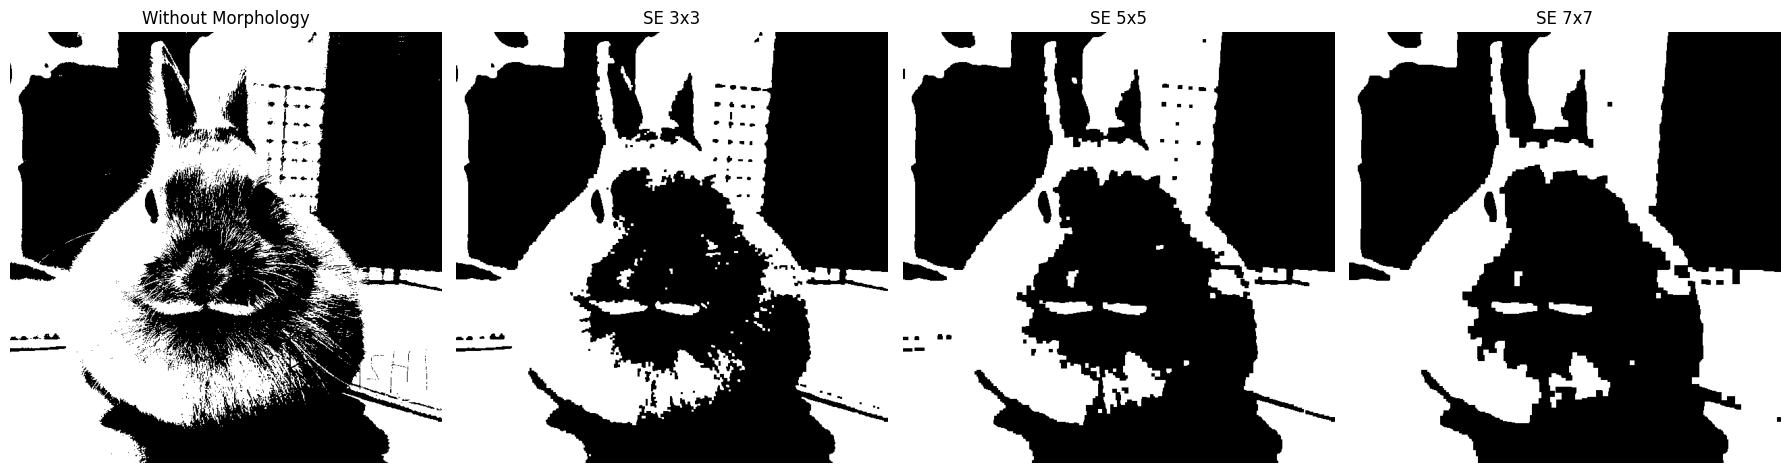

In [64]:
# Menguji opening dan closing dengan ukuran SE berbeda
result_3 = closing(opening(segmented, SE_3), SE_3)
result_5 = closing(opening(segmented, SE_5), SE_5)
result_7 = closing(opening(segmented, SE_7), SE_7)

# Menampilkan perbandingan
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(segmented, cmap="gray")
axes[0].set_title("Without Morphology")

axes[1].imshow(result_3, cmap="gray")
axes[1].set_title("SE 3x3")

axes[2].imshow(result_5, cmap="gray")
axes[2].set_title("SE 5x5")

axes[3].imshow(result_7, cmap="gray")
axes[3].set_title("SE 7x7")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [65]:
def count_components(image, min_size=30):
    binary = image > 0

    height, width = binary.shape
    visited = np.zeros(binary.shape, dtype=bool)

    component_sizes = []

    # Delapan arah tetangga
    neighbors = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),           (0, 1),
        (1, -1),  (1, 0),  (1, 1)
    ]

    for y in range(height):
        for x in range(width):

            if binary[y, x] and not visited[y, x]:

                queue = deque([(y, x)])
                visited[y, x] = True

                size = 0

                while queue:
                    current_y, current_x = queue.popleft()
                    size += 1

                    for dy, dx in neighbors:
                        ny = current_y + dy
                        nx = current_x + dx

                        if (
                            0 <= ny < height and
                            0 <= nx < width and
                            binary[ny, nx] and
                            not visited[ny, nx]
                        ):
                            visited[ny, nx] = True
                            queue.append((ny, nx))

                component_sizes.append(size)

    total_components = len(component_sizes)

    small_components = sum(
        size < min_size for size in component_sizes
    )

    return total_components, small_components, component_sizes

In [66]:
# Menghitung connected components untuk setiap hasil
methods = {
    "Without Morphology": segmented,
    "SE 3x3": result_3,
    "SE 5x5": result_5,
    "SE 7x7": result_7
}

print(
    f"{'Method':<22} "
    f"{'Total Components':<20} "
    f"{'Small Components':<20} "
    f"{'White Pixels (%)':<18}"
)

print("-" * 80)

for name, result in methods.items():

    total, small, sizes = count_components(result)

    white_percentage = np.mean(result > 0) * 100

    print(
        f"{name:<22} "
        f"{total:<20} "
        f"{small:<20} "
        f"{white_percentage:<18.2f}"
    )

Method                 Total Components     Small Components     White Pixels (%)  
--------------------------------------------------------------------------------
Without Morphology     1141                 1110                 45.98             
SE 3x3                 46                   30                   43.37             
SE 5x5                 15                   2                    41.80             
SE 7x7                 7                    0                    40.94             


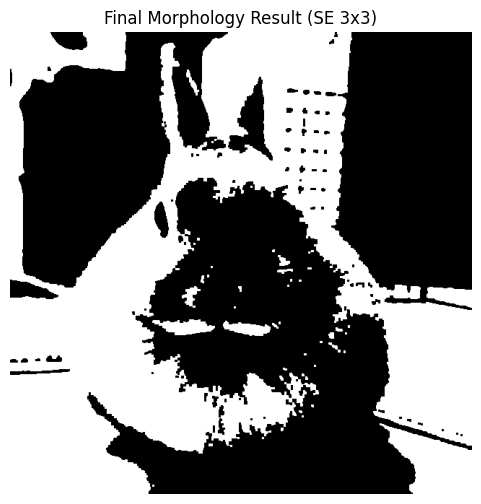

In [67]:
# Menentukan ukuran structuring element yang digunakan
# Ubah nilainya menjadi 3, 5, atau 7 berdasarkan hasil pengamatan

SE_SIZE = 3

if SE_SIZE == 3:
    selected_se = SE_3
elif SE_SIZE == 5:
    selected_se = SE_5
else:
    selected_se = SE_7

# Menerapkan opening kemudian closing
morphology_image = closing(
    opening(segmented, selected_se),
    selected_se
)

# Menampilkan hasil akhir
plt.figure(figsize=(6, 6))
plt.imshow(morphology_image, cmap="gray")
plt.title(f"Final Morphology Result (SE {SE_SIZE}x{SE_SIZE})")
plt.axis("off")
plt.show()

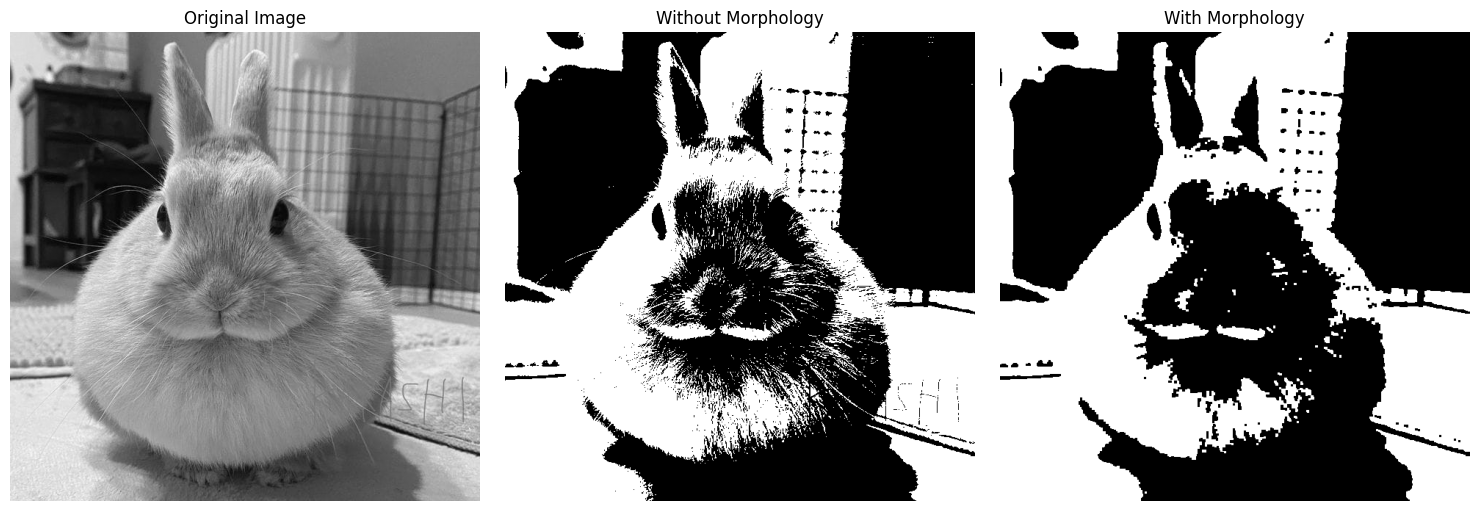

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(segmented, cmap="gray")
axes[1].set_title("Without Morphology")

axes[2].imshow(morphology_image, cmap="gray")
axes[2].set_title("With Morphology")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [69]:
# Menghitung komponen sebelum dan sesudah morphology
before_total, before_small, before_sizes = count_components(segmented)

after_total, after_small, after_sizes = count_components(morphology_image)

# Menghitung jumlah piksel putih
before_white = np.sum(segmented > 0)
after_white = np.sum(morphology_image > 0)

# Menghitung persentase piksel putih
before_percentage = (before_white / segmented.size) * 100
after_percentage = (after_white / morphology_image.size) * 100

print("ANALISIS HASIL MORPHOLOGY")
print("-------------------------")

print("Nilai threshold Otsu:", T)
print("Ukuran Structuring Element:", SE_SIZE, "x", SE_SIZE)

print("\nSebelum Morphology:")
print("Total components:", before_total)
print("Small components:", before_small)
print("White pixels:", before_white)
print("White pixel percentage:", round(before_percentage, 2), "%")

print("\nSesudah Morphology:")
print("Total components:", after_total)
print("Small components:", after_small)
print("White pixels:", after_white)
print("White pixel percentage:", round(after_percentage, 2), "%")

ANALISIS HASIL MORPHOLOGY
-------------------------
Nilai threshold Otsu: 131
Ukuran Structuring Element: 3 x 3

Sebelum Morphology:
Total components: 1141
Small components: 1110
White pixels: 188327
White pixel percentage: 45.98 %

Sesudah Morphology:
Total components: 46
Small components: 30
White pixels: 177640
White pixel percentage: 43.37 %
